# Baseline Model Comparison: Random Forest vs XGBoost vs LightGBM

Goal: see how far tabular models get on the features from the preprocessing notebook, and where they fail.
Inputs: `processed/{train,val,test}_tree.parquet`, `feature_sets.json`, `class_info.json` (from `preprocessing.ipynb`).

Model choices use validation only. The test split is used only to report results. `aux_*` and `strat_*` columns are never features.

## 1. Configuration

In [7]:
import json
import time
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             brier_score_loss, matthews_corrcoef, balanced_accuracy_score)
from sklearn.model_selection import ParameterSampler, GroupKFold
from sklearn.calibration import calibration_curve
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# folders
PROC_DIR = "processed"               # output of the preprocessing notebook
RES_DIR = "results"
os.makedirs(RES_DIR, exist_ok=True)

# experiment settings
SEED = 42
FEATURE_SET = "FS_B"                 # main comparison; FS_A and FS_C are compared in the ablation
N_JOBS = -1
RF_MAX_TRAIN_ROWS = 400000           # random forest gets a smaller sample (boosters use all rows)
SWEEP_MAX_TRAIN_ROWS = 300000        # rows per fit in the ablation and learning curve
USE_CLASS_WEIGHTS = True             # use the class weights from class_info.json
THRESHOLD_BETA = 2.0                 # F-beta used to pick the threshold on validation (2 = recall counts 4x precision)
TUNE = False                         # True: small random search per model on validation (slower)
N_TUNE_ITER = 10
K_LIST = (1, 3, 5, 10)               # fixed K for Precision@K and Recall@K
N_BOOT = 100                         # case-level bootstrap draws
RUN_ABLATION = True
RUN_PERM_IMPORTANCE = True
RUN_LEARNING_CURVE = True
RUN_GROUP_CV = False                 # 5-fold CV grouped by case on train+val (slower)

# "good enough" targets, checked on the test split in section 11
TARGETS = {"pr_auc": 0.90, "recall": 0.95, "precision": 0.80, "r_precision": 0.85}

print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__)

xgboost 3.4.0 | lightgbm 4.7.0


## 2. Load data

Reads the preprocessing outputs and checks that the splits share no case and no forbidden column is a feature.

In [8]:
def read_table(name):
    parquet_path = PROC_DIR + "/" + name + ".parquet"
    if os.path.exists(parquet_path):
        return pd.read_parquet(parquet_path)
    return pd.read_csv(PROC_DIR + "/" + name + ".csv.gz")


tr = read_table("train_tree")
va = read_table("val_tree")
te = read_table("test_tree")

fs = json.load(open(PROC_DIR + "/feature_sets.json"))
class_info = json.load(open(PROC_DIR + "/class_info.json"))
TARGET = fs["target"]
FEATS = fs[FEATURE_SET]

# the splits must not share any case
assert set(tr["case_id"]).isdisjoint(set(va["case_id"]))
assert set(tr["case_id"]).isdisjoint(set(te["case_id"]))
assert set(va["case_id"]).isdisjoint(set(te["case_id"]))

# feature lists must not contain forbidden columns
not_allowed = [TARGET, "case_id", "step", "agent_id", "ts_id"]
for name in ["FS_A", "FS_B", "FS_C"]:
    for c in fs[name]:
        assert not c.startswith("aux_") and not c.startswith("strat_"), c
        assert c not in not_allowed, c
        assert c in tr.columns, c

summary = pd.DataFrame({
    "rows": [len(tr), len(va), len(te)],
    "cases": [tr["case_id"].nunique(), va["case_id"].nunique(), te["case_id"].nunique()],
    "snapshots": [tr["ts_id"].nunique(), va["ts_id"].nunique(), te["ts_id"].nunique()],
    "critical_share": [tr[TARGET].mean(), va[TARGET].mean(), te[TARGET].mean()],
}, index=["train", "val", "test"])
display(summary)
print(FEATURE_SET, ":", len(FEATS), "features")

if USE_CLASS_WEIGHTS:
    scale_pos_weight = class_info["train_class_weights"]["scale_pos_weight"]
else:
    scale_pos_weight = 1.0
print("scale_pos_weight =", round(scale_pos_weight, 3))


def case_balanced_sample(d, max_rows, seed):
    """Takes the same fraction of rows from every case, so that all cases stay represented."""
    if len(d) <= max_rows:
        return d
    frac = max_rows / len(d)
    parts = []
    for case_id, rows_of_case in d.groupby("case_id"):
        parts.append(rows_of_case.sample(frac=frac, random_state=seed))
    return pd.concat(parts)


tr_rf = case_balanced_sample(tr, RF_MAX_TRAIN_ROWS, SEED)
print("random forest training rows:", len(tr_rf), "of", len(tr))

,rows,cases,snapshots,critical_share
train,998064,60,22691,0.3833
val,313396,20,7279,0.3834
test,327706,20,7761,0.4137


FS_B : 45 features
scale_pos_weight = 1.609
random forest training rows: 400000 of 998064


## 3. Metric functions

- **Classification:** PR-AUC is the main metric. Precision, recall, F1, F2, MCC, balanced accuracy and Brier score are reported at a threshold.
- **Ranking (per snapshot):** Precision@K, Recall@K, R-precision (K = number of critical agents), mean average precision and top-1 hit rate. Ties are broken at random.

In [9]:
def fbeta(precision, recall, beta):
    return (1 + beta ** 2) * precision * recall / max(beta ** 2 * precision + recall, 1e-12)


def best_threshold(y, p, beta=THRESHOLD_BETA):
    """Threshold with the highest F-beta score."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    precision = precision[:-1]
    recall = recall[:-1]
    f = (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall + 1e-12)
    return float(thresholds[int(np.argmax(f))])


def clf_metrics(y, p, thr):
    """Classification metrics for scores p at threshold thr."""
    y = np.asarray(y)
    p = np.asarray(p)
    pred = (p >= thr).astype(int)

    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    # some metrics need both classes to be present
    both_classes = len(np.unique(y)) == 2

    result = {}
    result["pr_auc"] = average_precision_score(y, p) if both_classes else np.nan
    result["roc_auc"] = roc_auc_score(y, p) if both_classes else np.nan
    result["precision"] = precision
    result["recall"] = recall
    result["f1"] = fbeta(precision, recall, 1)
    result["f2"] = fbeta(precision, recall, 2)
    result["specificity"] = tn / max(tn + fp, 1)
    result["mcc"] = matthews_corrcoef(y, pred) if both_classes else np.nan
    result["balanced_acc"] = balanced_accuracy_score(y, pred) if both_classes else np.nan
    result["brier"] = brier_score_loss(y, np.clip(p, 0, 1)) if both_classes else np.nan
    result["prevalence"] = y.mean()
    result["threshold"] = thr
    return result


def rank_metrics(ts_id, y, score, ks=K_LIST, seed=SEED):
    """Ranking metrics per snapshot, averaged over snapshots with at least one critical agent.
    Written with numpy (no loop over snapshots) because it is called many times."""
    ts_id = np.asarray(ts_id)
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)

    # random numbers used to break ties
    tie = np.random.default_rng(seed).random(len(y))

    # sort by snapshot, then by score (high first), then by the random tie-break
    order = np.lexsort((tie, -score, ts_id))
    t = ts_id[order]
    yy = y[order]

    # where every snapshot starts in the sorted arrays, and how many agents it has
    start = np.r_[0, np.flatnonzero(np.diff(t)) + 1]
    size = np.diff(np.r_[start, len(t)])

    # rank of every agent inside its snapshot (0 = highest score)
    rank = np.arange(len(t)) - np.repeat(start, size)

    # number of critical agents in each snapshot; snapshots without any are ignored
    n_pos = np.add.reduceat(yy, start)
    valid = n_pos > 0

    result = {}
    for K in ks:
        hits_in_top_k = np.add.reduceat(yy * (rank < K), start)
        result["P@" + str(K)] = float(np.mean((hits_in_top_k / np.minimum(K, size))[valid]))
        result["R@" + str(K)] = float(np.mean((hits_in_top_k / np.maximum(n_pos, 1))[valid]))

    # R-precision: K = number of critical agents in the snapshot
    hits_r = np.add.reduceat(yy * (rank < np.repeat(n_pos, size)), start)
    result["r_precision"] = float(np.mean((hits_r / np.maximum(n_pos, 1))[valid]))

    # mean average precision
    cum_hits = np.cumsum(yy)
    if len(start) > 1:
        hits_before_snapshot = np.r_[0, cum_hits[start[1:] - 1]]
    else:
        hits_before_snapshot = np.array([0])
    hits_so_far = cum_hits - np.repeat(hits_before_snapshot, size)
    precision_at_rank = hits_so_far / (rank + 1)
    ap = np.add.reduceat(precision_at_rank * yy, start) / np.maximum(n_pos, 1)
    result["map"] = float(np.mean(ap[valid]))

    # is the top ranked agent critical?
    result["top1_hit"] = float(np.mean(yy[start][valid]))
    result["n_snapshots"] = int(valid.sum())
    return result


# quick self-test on a toy example: two snapshots with 6 agents and 2 critical agents each
toy_ts = np.repeat([0, 1], 6)
toy_y = np.tile([1, 1, 0, 0, 0, 0], 2)
perfect = np.tile([6, 5, 4, 3, 2, 1], 2)
worst = np.tile([1, 2, 3, 4, 5, 6], 2)
assert abs(rank_metrics(toy_ts, toy_y, perfect)["r_precision"] - 1) < 1e-9
assert rank_metrics(toy_ts, toy_y, worst)["r_precision"] == 0
assert abs(rank_metrics(toy_ts, toy_y, perfect)["map"] - 1) < 1e-9
print("ranking metric self-test passed")

ranking metric self-test passed


## 4. Baselines

- **Random:** PR-AUC equals the share of critical rows.
- **Best single feature:** the training feature with the highest PR-AUC, used directly as a score.
- **`criticality_score` heuristic:** the dataset's own score. It is not a model input.

In [10]:
# PR-AUC of every feature used on its own (on a sample of the training rows)
sub_tr = tr.sample(n=min(200000, len(tr)), random_state=SEED)
y_sub = sub_tr[TARGET].to_numpy()

single_pr_auc = {}
single_sign = {}
for c in FEATS:
    x = sub_tr[c].to_numpy(float)
    if x.max() == x.min():
        continue
    auc = roc_auc_score(y_sub, x)
    if auc >= 0.5:
        sign = 1
    else:
        sign = -1               # a low value of this feature means "critical"
    single_pr_auc[c] = average_precision_score(y_sub, sign * x)
    single_sign[c] = sign

best_feat = max(single_pr_auc, key=single_pr_auc.get)
best_sign = single_sign[best_feat]
print("best single training feature:", best_feat, "| train PR-AUC", round(single_pr_auc[best_feat], 3), "| sign", best_sign)


def baseline_scores(d):
    return {"random": np.random.default_rng(SEED).random(len(d)),
            "single: " + best_feat: best_sign * d[best_feat].to_numpy(float),
            "heuristic: criticality_score": d["aux_criticality_score"].to_numpy(float)}

best single training feature: weighted_density_z | train PR-AUC 0.799 | sign 1


## 5. Train the models

Random Forest (balanced class weights), XGBoost and LightGBM (medium trees, row/column subsampling, early stopping on validation PR-AUC). `TUNE = True` runs a small random search first. The test split is never used here.

In [11]:
Xtr = tr[FEATS]
ytr = tr[TARGET].to_numpy()
Xva = va[FEATS]
yva = va[TARGET].to_numpy()
Xte = te[FEATS]
yte = te[TARGET].to_numpy()
Xtr_rf = tr_rf[FEATS]
ytr_rf = tr_rf[TARGET].to_numpy()


def make_rf(**changes):
    params = dict(n_estimators=300, max_depth=None, min_samples_leaf=20, max_features="sqrt",
                  n_jobs=N_JOBS, random_state=SEED)
    if USE_CLASS_WEIGHTS:
        params["class_weight"] = "balanced_subsample"
    params.update(changes)
    return RandomForestClassifier(**params)


def make_xgb(**changes):
    params = dict(n_estimators=2000, learning_rate=0.05, max_depth=7, min_child_weight=20, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=2.0, tree_method="hist", n_jobs=N_JOBS, random_state=SEED,
                  scale_pos_weight=scale_pos_weight, eval_metric="aucpr", early_stopping_rounds=50)
    params.update(changes)
    return xgb.XGBClassifier(**params)


def make_lgb(**changes):
    params = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0, n_jobs=N_JOBS, random_state=SEED,
                  scale_pos_weight=scale_pos_weight, verbose=-1)
    params.update(changes)
    return lgb.LGBMClassifier(**params)


def fit_model(name, params, X_train, y_train, X_val=None, y_val=None):
    """Fits one model and returns (model, seconds). The boosters use X_val to stop early."""
    if X_val is None:
        X_val = Xva
        y_val = yva
    t0 = time.time()
    if name == "RandomForest":
        model = make_rf(**params).fit(X_train, y_train)
    elif name == "XGBoost":
        model = make_xgb(**params).fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    else:
        model = make_lgb(**params).fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="average_precision",
                                       callbacks=[lgb.early_stopping(50, verbose=False)])
    return model, time.time() - t0


def fit_default(name, params):
    """Fits a model on the standard training data (random forest: smaller sample, boosters: all rows)."""
    if name == "RandomForest":
        return fit_model(name, params, Xtr_rf, ytr_rf)
    return fit_model(name, params, Xtr, ytr)


def predict(model, X):
    return model.predict_proba(X)[:, 1]


# search spaces for TUNE = True
SPACES = {
    "RandomForest": {"max_depth": [12, 20, 30, None], "min_samples_leaf": [5, 20, 50, 100], "max_features": ["sqrt", 0.3, 0.5]},
    "XGBoost": {"max_depth": [4, 6, 8, 10], "learning_rate": [0.03, 0.05, 0.1], "min_child_weight": [5, 20, 50, 100],
                "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0], "reg_lambda": [1, 2, 10]},
    "LightGBM": {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.03, 0.05, 0.1], "min_child_samples": [20, 100, 300],
                 "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0], "reg_lambda": [1, 2, 10]},
}
MODELS = ["RandomForest", "XGBoost", "LightGBM"]

best_params = {}
for name in MODELS:
    best_params[name] = {}

if TUNE:
    for name in MODELS:
        best_score = -1
        for params in ParameterSampler(SPACES[name], n_iter=N_TUNE_ITER, random_state=SEED):
            model, _ = fit_default(name, params)
            score = average_precision_score(yva, predict(model, Xva))
            if score > best_score:
                best_score = score
                best_params[name] = params
        print(name, ": best validation PR-AUC", round(best_score, 4), "with", best_params[name])

models = {}
fit_time = {}
for name in MODELS:
    models[name], fit_time[name] = fit_default(name, best_params[name])
    extra = ""
    if name == "XGBoost":
        extra = " (best iteration " + str(models[name].best_iteration) + ")"
    if name == "LightGBM":
        extra = " (best iteration " + str(models[name].best_iteration_) + ")"
    print(name, "trained in", round(fit_time[name], 1), "s", extra)

RandomForest trained in 107.9 s 
XGBoost trained in 30.1 s  (best iteration 468)
LightGBM trained in 13.9 s  (best iteration 242)


## 6. Scores, thresholds and validation results

The threshold is chosen on validation by maximising F2 (recall counts more). F1 and "recall >= 0.95" thresholds are also computed. The F2 one is used from here on.

In [24]:
def operating_points(y, p):
    """Three possible thresholds chosen on the data (y, p)."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    precision = precision[:-1]
    recall = recall[:-1]
    out = {}
    for label, beta in [("F2", 2.0), ("F1", 1.0)]:
        f = (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall + 1e-12)
        out[label] = float(thresholds[int(np.argmax(f))])
    ok = recall >= 0.95
    if ok.any():
        out["recall>=0.95"] = float(thresholds[ok][np.argmax(precision[ok])])
    else:
        out["recall>=0.95"] = float(thresholds.min())
    return out


# scores of every model on train (sample), validation and test
scores = {"val": {}, "test": {}, "train": {}}
for name in MODELS:
    scores["val"][name] = predict(models[name], Xva)
    scores["test"][name] = predict(models[name], Xte)
    scores["train"][name] = predict(models[name], Xtr.iloc[::5])      # every 5th training row is enough for the gap check
ytr_s = ytr[::5]

# add the baselines
for split, d in [("val", va), ("test", te)]:
    baselines = baseline_scores(d)
    for k in baselines:
        scores[split][k] = baselines[k]
scores["train"]["heuristic: criticality_score"] = tr["aux_criticality_score"].to_numpy(float)[::5]

# thresholds are chosen on validation
ops = {}
for name in scores["val"]:
    ops[name] = operating_points(yva, scores["val"][name])
THR = {}
for name in ops:
    THR[name] = ops[name]["F2"]

val_rows = []
for name in scores["val"]:
    p = scores["val"][name]
    row = clf_metrics(yva, p, THR[name])
    row.update(rank_metrics(va["ts_id"].to_numpy(), yva, p))
    row["model"] = name
    val_rows.append(row)
val_tbl = pd.DataFrame(val_rows).set_index("model")

display(val_tbl[["pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "mcc", "r_precision", "map", "top1_hit", "P@5", "R@5", "brier"]])
val_tbl.to_csv(RES_DIR + "/validation_metrics.csv")

,pr_auc,roc_auc,precision,recall,f1,f2,mcc,r_precision,map,top1_hit,P@5,R@5,brier
model,,,,,,,,,,,,,
RandomForest,0.9653,0.9714,0.7949,0.9416,0.8621,0.9081,0.7720,0.8954,0.9500,0.9890,0.9715,0.3822,0.0611
XGBoost,0.9760,0.9816,0.8223,0.9572,0.8847,0.9268,0.8104,0.9187,0.9618,0.9887,0.9763,0.3846,0.0466
LightGBM,0.9756,0.9811,0.8449,0.9494,0.8941,0.9265,0.8258,0.9154,0.9603,0.9876,0.9752,0.3840,0.0471
random,0.3816,0.4980,0.3834,1.0000,0.5543,0.7566,0.0020,0.3743,0.4326,0.3686,0.3726,0.1428,0.3343
single: weighted_density_z,0.7841,0.8599,0.5396,0.9212,0.6806,0.8071,0.4422,0.7382,0.8207,0.9011,0.8749,0.3331,0.1548
heuristic: criticality_score,0.9989,0.9993,0.9460,0.9985,0.9716,0.9876,0.9541,0.9980,0.9997,1.0000,1.0000,0.4024,0.0320


## 7. Train, validation and test PR-AUC

A big train-validation gap means the model memorised the training cases. The test column is only reported, not used to choose anything.

,train,val,test,train-val gap,val-test gap
model,,,,,
RandomForest,0.9976,0.9653,0.9781,0.0323,-0.0128
XGBoost,0.9991,0.9760,0.9866,0.0231,-0.0106
LightGBM,0.9974,0.9756,0.9862,0.0218,-0.0106
random,NaN,0.3816,0.4135,NaN,-0.0319
single: weighted_density_z,NaN,0.7841,0.7928,NaN,-0.0087
heuristic: criticality_score,0.9980,0.9989,0.9972,-0.0009,0.0018


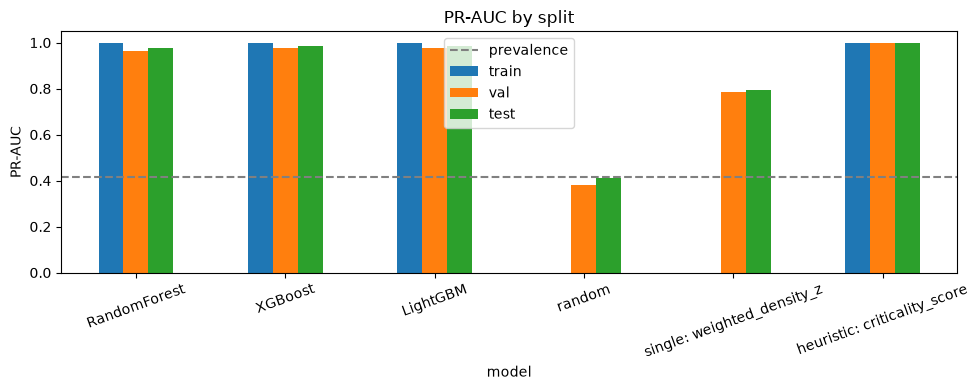

In [13]:
gap_rows = []
for name in scores["val"]:
    row = {"model": name}
    if name in scores["train"]:
        row["train"] = average_precision_score(ytr_s, scores["train"][name])
    else:
        row["train"] = np.nan
    row["val"] = average_precision_score(yva, scores["val"][name])
    row["test"] = average_precision_score(yte, scores["test"][name])
    gap_rows.append(row)

gap = pd.DataFrame(gap_rows).set_index("model")
gap["train-val gap"] = gap["train"] - gap["val"]
gap["val-test gap"] = gap["val"] - gap["test"]
display(gap)

ax = gap[["train", "val", "test"]].plot(kind="bar", figsize=(10, 4), rot=20)
ax.axhline(yte.mean(), color="grey", ls="--", label="prevalence")
ax.set_ylabel("PR-AUC")
ax.set_title("PR-AUC by split")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Test results with case-level uncertainty

The test split has only about 20 cases. Cases are resampled with replacement (`N_BOOT` times) to get 95% intervals and paired differences between models.

In [14]:
te_y = yte
ts_te = te["ts_id"].to_numpy()
cases_te = te["case_id"].to_numpy()
case_ids = np.unique(cases_te)

# row positions of every test case
case_rows = {}
for c in case_ids:
    case_rows[c] = np.flatnonzero(cases_te == c)

# test metrics at the thresholds fixed on validation
test_rows = []
for name in scores["test"]:
    p = scores["test"][name]
    row = clf_metrics(te_y, p, THR[name])
    row.update(rank_metrics(ts_te, te_y, p))
    row["model"] = name
    test_rows.append(row)
test_tbl = pd.DataFrame(test_rows).set_index("model")
test_tbl.to_csv(RES_DIR + "/test_metrics.csv")


def boot_stats(idx, name):
    """PR-AUC, recall, precision and R-precision of one model on the resampled rows idx."""
    p = scores["test"][name][idx]
    y = te_y[idx]
    thr = THR[name]
    tp = ((p >= thr) & (y == 1)).sum()
    result = {}
    result["pr_auc"] = average_precision_score(y, p)
    result["recall"] = tp / max((y == 1).sum(), 1)
    result["precision"] = tp / max((p >= thr).sum(), 1)
    result["r_precision"] = rank_metrics(ts_te[idx], y, p)["r_precision"]
    return result


# the same resampled cases are used for every model
boot = {}
for name in scores["test"]:
    boot[name] = []
rb = np.random.default_rng(SEED)
for b in range(N_BOOT):
    drawn_cases = rb.choice(case_ids, size=len(case_ids), replace=True)
    idx = np.concatenate([case_rows[c] for c in drawn_cases])
    for name in scores["test"]:
        boot[name].append(boot_stats(idx, name))

boot_df = {}
for name in boot:
    boot_df[name] = pd.DataFrame(boot[name])

# 95% intervals
ci_rows = []
for name in boot_df:
    row = {"model": name}
    for m in ["pr_auc", "recall", "precision", "r_precision"]:
        row[m] = test_tbl.loc[name, m]
        row[m + "_lo"] = boot_df[name][m].quantile(0.025)
        row[m + "_hi"] = boot_df[name][m].quantile(0.975)
    ci_rows.append(row)
ci = pd.DataFrame(ci_rows).set_index("model")

ci_cols = []
for m in ["pr_auc", "recall", "precision", "r_precision"]:
    ci_cols = ci_cols + [m, m + "_lo", m + "_hi"]

print("TEST, thresholds fixed on validation; 95% case-bootstrap intervals (", N_BOOT, "draws over", len(case_ids), "cases ):")
display(ci[ci_cols])
display(test_tbl[["pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "specificity", "mcc", "balanced_acc", "brier",
                  "P@1", "P@3", "P@5", "P@10", "R@5", "R@10", "r_precision", "map", "top1_hit"]])
ci.to_csv(RES_DIR + "/test_metrics_ci.csv")

# paired differences between the learned models
diff_rows = []
for a, b in [("XGBoost", "RandomForest"), ("LightGBM", "RandomForest"), ("LightGBM", "XGBoost")]:
    for m in ["pr_auc", "recall", "r_precision"]:
        d = boot_df[a][m].to_numpy() - boot_df[b][m].to_numpy()
        lo = np.quantile(d, 0.025)
        hi = np.quantile(d, 0.975)
        diff_rows.append({"comparison": a + " - " + b, "metric": m, "mean_diff": d.mean(), "lo": lo, "hi": hi,
                          "significant (CI excludes 0)": bool(lo > 0 or hi < 0)})
diff_df = pd.DataFrame(diff_rows)
display(diff_df)
diff_df.to_csv(RES_DIR + "/paired_differences.csv", index=False)

TEST, thresholds fixed on validation; 95% case-bootstrap intervals ( 100 draws over 20 cases ):


,pr_auc,pr_auc_lo,pr_auc_hi,recall,recall_lo,recall_hi,precision,precision_lo,precision_hi,r_precision,r_precision_lo,r_precision_hi
model,,,,,,,,,,,,
RandomForest,0.9781,0.9637,0.9862,0.9643,0.9456,0.9778,0.8331,0.7858,0.8599,0.9105,0.8894,0.9287
XGBoost,0.9866,0.9771,0.9930,0.9772,0.9629,0.9903,0.8671,0.8241,0.8920,0.9374,0.9182,0.9532
LightGBM,0.9862,0.9762,0.9925,0.9706,0.9530,0.9855,0.8826,0.8436,0.9056,0.9337,0.9137,0.9500
random,0.4135,0.3862,0.4405,1.0000,1.0000,1.0000,0.4137,0.3872,0.4404,0.4153,0.3869,0.4446
single: weighted_density_z,0.7928,0.7430,0.8213,0.9437,0.9279,0.9534,0.5935,0.5400,0.6371,0.7668,0.7260,0.7904
heuristic: criticality_score,0.9972,0.9954,0.9996,0.9783,0.9369,1.0000,0.9719,0.9498,0.9918,0.9994,0.9989,1.0000


,pr_auc,roc_auc,precision,recall,f1,f2,specificity,mcc,balanced_acc,brier,P@1,P@3,P@5,P@10,R@5,R@10,r_precision,map,top1_hit
model,,,,,,,,,,,,,,,,,,,
RandomForest,0.9781,0.9821,0.8331,0.9643,0.8939,0.9349,0.8637,0.8163,0.9140,0.0538,0.9823,0.9727,0.9617,0.8802,0.3876,0.6504,0.9105,0.9561,0.9823
XGBoost,0.9866,0.9896,0.8671,0.9772,0.9189,0.9530,0.8943,0.8604,0.9358,0.0368,0.9872,0.9803,0.9728,0.8922,0.3944,0.6625,0.9374,0.9714,0.9872
LightGBM,0.9862,0.9892,0.8826,0.9706,0.9245,0.9516,0.9089,0.8698,0.9397,0.0373,0.9872,0.9816,0.9712,0.8900,0.3932,0.6602,0.9337,0.9701,0.9872
random,0.4135,0.5007,0.4137,1.0000,0.5852,0.7791,0.0000,-0.0004,0.5000,0.3329,0.4123,0.4149,0.4136,0.4145,0.1652,0.3310,0.4153,0.4720,0.4123
single: weighted_density_z,0.7928,0.8731,0.5935,0.9437,0.7287,0.8441,0.5439,0.5061,0.7438,0.1513,0.8682,0.8737,0.8439,0.7750,0.3311,0.5634,0.7668,0.8347,0.8682
heuristic: criticality_score,0.9972,0.9981,0.9719,0.9783,0.9751,0.9770,0.9800,0.9574,0.9792,0.0586,1.0000,1.0000,1.0000,0.9065,0.4136,0.6768,0.9994,1.0000,1.0000


,comparison,metric,mean_diff,lo,hi,significant (CI excludes 0)
0,XGBoost - RandomForest,pr_auc,0.0090,0.0064,0.0135,True
1,XGBoost - RandomForest,recall,0.0134,0.0080,0.0214,True
2,XGBoost - RandomForest,r_precision,0.0273,0.0215,0.0321,True
3,LightGBM - RandomForest,pr_auc,0.0085,0.0059,0.0127,True
4,LightGBM - RandomForest,recall,0.0065,0.0012,0.0116,True
5,LightGBM - RandomForest,r_precision,0.0236,0.0185,0.0282,True
6,LightGBM - XGBoost,pr_auc,-0.0005,-0.0014,0.0003,False
7,LightGBM - XGBoost,recall,-0.0068,-0.0097,-0.0043,True
8,LightGBM - XGBoost,r_precision,-0.0037,-0.0051,-0.0027,True


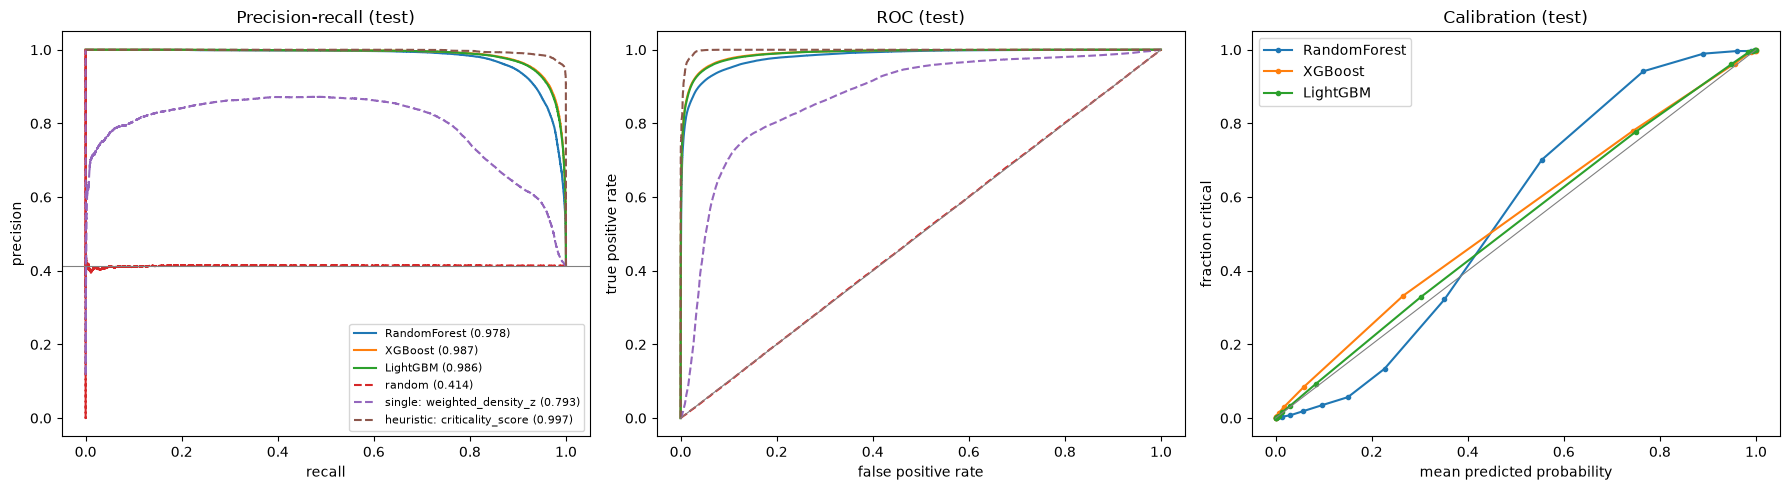

In [15]:
# precision-recall curve, ROC curve and calibration curve on the test split
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name in scores["test"]:
    p = scores["test"][name]
    precision, recall, _ = precision_recall_curve(te_y, p)
    fpr, tpr, _ = roc_curve(te_y, p)
    if name in MODELS:
        line = "-"
    else:
        line = "--"       # baselines are dashed

    axes[0].plot(recall, precision, line, label=name + " (" + str(round(average_precision_score(te_y, p), 3)) + ")")
    axes[1].plot(fpr, tpr, line, label=name)
    if name in MODELS:
        frac_critical, mean_pred = calibration_curve(te_y, np.clip(p, 0, 1), n_bins=15, strategy="quantile")
        axes[2].plot(mean_pred, frac_critical, marker="o", ms=3, label=name)

axes[0].axhline(te_y.mean(), color="grey", lw=0.8)
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title("Precision-recall (test)")
axes[0].legend(fontsize=8)

axes[1].plot([0, 1], [0, 1], color="grey", lw=0.8)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC (test)")

axes[2].plot([0, 1], [0, 1], color="grey", lw=0.8)
axes[2].set_xlabel("mean predicted probability")
axes[2].set_ylabel("fraction critical")
axes[2].set_title("Calibration (test)")
axes[2].legend()
plt.tight_layout()
plt.show()

## 9. Subsets (robustness)

Subsets are defined per case or snapshot, so snapshots are never split. Cut points for obstacles and clutter come from the training cases. Thresholds are the ones fixed on the full validation set.

In [16]:
def snapshot_info(d):
    """Per-row information about the snapshot the row belongs to."""
    info = pd.DataFrame({"case_id": d["case_id"], "step": d["step"]})
    info["n_alive"] = d.groupby("ts_id")["agent_id"].transform("size")
    case_last_step = d.groupby("case_id")["step"].transform("max").replace(0, 1)
    info["t_norm"] = d["step"] / case_last_step                  # 0 = start of the mission, 1 = end
    info["n_lost"] = d["strat_num_agents"] - info["n_alive"]
    return info


# terciles (cut points at 1/3 and 2/3) of the environment variables, from the training cases
tr_cases = tr.drop_duplicates("case_id")
cut = {}
for c in ["strat_clutter_index", "strat_obstacle_density", "strat_n_obstacles"]:
    cut[c] = tr_cases[c].quantile([1 / 3, 2 / 3]).to_numpy()


def tercile(x, col, labels):
    low, high = cut[col]
    return np.where(x <= low, labels[0], np.where(x <= high, labels[1], labels[2]))


def build_subsets(d):
    """Returns a dict: subset name -> True/False array over the rows of d."""
    info = snapshot_info(d)
    S = {}

    for a in ["none", "light", "medium", "heavy"]:
        S["attrition: " + a] = (d["strat_attrition"] == a).to_numpy()

    size_groups = {"small (18-30)": (0, 30), "medium (37-52)": (31, 52), "large (60-75)": (53, 99)}
    for label in size_groups:
        low, high = size_groups[label]
        S["swarm size: " + label] = d["strat_num_agents"].between(low, high).to_numpy()

    env_groups = [("clutter", tercile(d["strat_clutter_index"].to_numpy(), "strat_clutter_index", ["low", "mid", "high"])),
                  ("obstacle density", tercile(d["strat_obstacle_density"].to_numpy(), "strat_obstacle_density", ["low", "mid", "high"])),
                  ("obstacle count", tercile(d["strat_n_obstacles"].to_numpy(), "strat_n_obstacles", ["few", "mid", "many"]))]
    for label, values in env_groups:
        for v in np.unique(values):
            S[label + ": " + v] = (values == v)
    S["no obstacles"] = (d["strat_n_obstacles"] == 0).to_numpy()

    phases = {"early (0-33%)": (0, 1 / 3), "middle (33-67%)": (1 / 3, 2 / 3), "late (67-100%)": (2 / 3, 1.01)}
    for label in phases:
        low, high = phases[label]
        S["mission phase: " + label] = ((info["t_norm"] >= low) & (info["t_norm"] < high)).to_numpy()

    S["agents already lost: none"] = (info["n_lost"] == 0).to_numpy()
    S["agents already lost: 1+"] = (info["n_lost"] >= 1).to_numpy()

    # connectivity of the swarm (only if this feature is in the table)
    if "swarm_mean_degree" in d.columns:
        q = tr["swarm_mean_degree"].quantile([1 / 3, 2 / 3]).to_numpy()
        S["connectivity: sparse"] = (d["swarm_mean_degree"] <= q[0]).to_numpy()
        S["connectivity: medium"] = ((d["swarm_mean_degree"] > q[0]) & (d["swarm_mean_degree"] <= q[1])).to_numpy()
        S["connectivity: dense"] = (d["swarm_mean_degree"] > q[1]).to_numpy()

    S["ALL"] = np.ones(len(d), dtype=bool)
    return S


def subset_table(d, score_dict, thr, split_name):
    """Metrics of every model on every subset of d."""
    S = build_subsets(d)
    y = d[TARGET].to_numpy()
    ts = d["ts_id"].to_numpy()
    rows = []
    for subset_name in S:
        m = S[subset_name]
        # skip tiny subsets and subsets with only one class
        if m.sum() < 200 or len(np.unique(y[m])) < 2:
            continue
        for model in score_dict:
            p = score_dict[model]
            r = clf_metrics(y[m], p[m], thr[model])
            rk = rank_metrics(ts[m], y[m], p[m])
            rows.append({"split": split_name, "subset": subset_name, "model": model,
                         "n_cases": d["case_id"][m].nunique(), "n_rows": int(m.sum()),
                         "prevalence": r["prevalence"], "pr_auc": r["pr_auc"], "roc_auc": r["roc_auc"],
                         "recall": r["recall"], "precision": r["precision"], "f2": r["f2"],
                         "r_precision": rk["r_precision"], "P@5": rk["P@5"], "top1_hit": rk["top1_hit"]})
    return pd.DataFrame(rows)


subs_test = subset_table(te, scores["test"], THR, "test")
subs_val = subset_table(va, scores["val"], THR, "val")
subs_test.to_csv(RES_DIR + "/subset_metrics_test.csv", index=False)
subs_val.to_csv(RES_DIR + "/subset_metrics_val.csv", index=False)

subset_order = list(dict.fromkeys(subs_test["subset"]))
only_models = subs_test[subs_test["model"].isin(MODELS)]
info_cols = subs_test[subs_test["model"] == "LightGBM"].set_index("subset")[["n_cases", "n_rows", "prevalence"]]

for metric in ["pr_auc", "recall", "r_precision"]:
    pivot = only_models.pivot(index="subset", columns="model", values=metric)
    print("\nTEST:", metric, "by subset")
    display(info_cols.join(pivot.reindex(subset_order)))


TEST: pr_auc by subset


,n_cases,n_rows,prevalence,LightGBM,RandomForest,XGBoost
subset,,,,,,
attrition: none,5,74613,0.3864,0.9924,0.9857,0.9935
attrition: light,5,86008,0.3951,0.9896,0.9822,0.9897
attrition: medium,5,88841,0.4388,0.9837,0.9771,0.9839
attrition: heavy,5,78244,0.4316,0.9831,0.9724,0.9835
swarm size: small (18-30),8,62805,0.4143,0.9599,0.9415,0.9627
swarm size: medium (37-52),5,79107,0.3739,0.9803,0.9675,0.9809
swarm size: large (60-75),7,185794,0.4304,0.9942,0.9893,0.9943
clutter: high,6,72147,0.3830,0.9542,0.9340,0.9557
clutter: low,6,96034,0.4224,0.9936,0.9875,0.9944



TEST: recall by subset


,n_cases,n_rows,prevalence,LightGBM,RandomForest,XGBoost
subset,,,,,,
attrition: none,5,74613,0.3864,0.9891,0.9847,0.9931
attrition: light,5,86008,0.3951,0.9901,0.9807,0.9945
attrition: medium,5,88841,0.4388,0.9518,0.9509,0.9597
attrition: heavy,5,78244,0.4316,0.9568,0.9460,0.9665
swarm size: small (18-30),8,62805,0.4143,0.9691,0.9650,0.9799
swarm size: medium (37-52),5,79107,0.3739,0.9541,0.9418,0.9640
swarm size: large (60-75),7,185794,0.4304,0.9771,0.9724,0.9812
clutter: high,6,72147,0.3830,0.9457,0.9306,0.9602
clutter: low,6,96034,0.4224,0.9837,0.9774,0.9879



TEST: r_precision by subset


,n_cases,n_rows,prevalence,LightGBM,RandomForest,XGBoost
subset,,,,,,
attrition: none,5,74613,0.3864,0.9517,0.9194,0.9554
attrition: light,5,86008,0.3951,0.9310,0.9097,0.9354
attrition: medium,5,88841,0.4388,0.9407,0.9245,0.9422
attrition: heavy,5,78244,0.4316,0.9144,0.8910,0.9193
swarm size: small (18-30),8,62805,0.4143,0.8999,0.8723,0.9064
swarm size: medium (37-52),5,79107,0.3739,0.9390,0.9134,0.9413
swarm size: large (60-75),7,185794,0.4304,0.9702,0.9537,0.9713
clutter: high,6,72147,0.3830,0.8827,0.8516,0.8872
clutter: low,6,96034,0.4224,0.9646,0.9459,0.9683


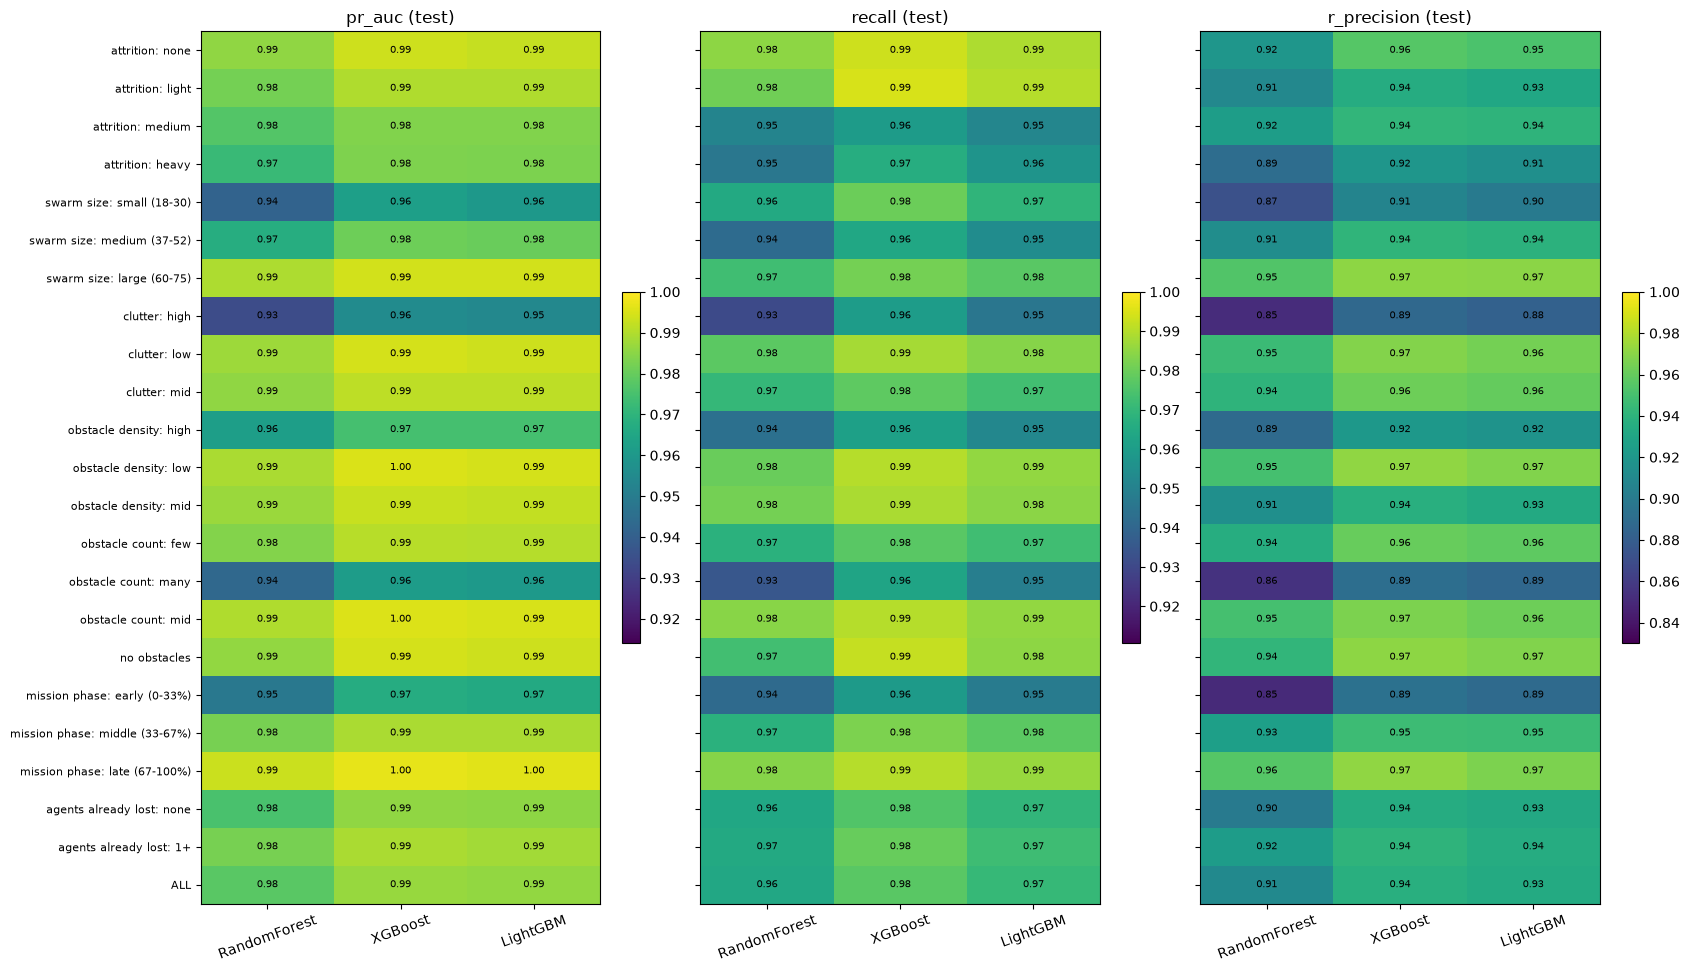

In [17]:
# heatmap of the three metrics for every subset and model
fig, axes = plt.subplots(1, 3, figsize=(17, 0.34 * len(subset_order) + 2))
metric_list = ["pr_auc", "recall", "r_precision"]
for k in range(3):
    ax = axes[k]
    metric = metric_list[k]
    h = only_models.pivot(index="subset", columns="model", values=metric).reindex(subset_order)[MODELS]

    im = ax.imshow(h.to_numpy(), cmap="viridis", vmin=max(np.nanmin(h.to_numpy()) - 0.02, 0), vmax=1, aspect="auto")
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels(MODELS, rotation=20)
    ax.set_title(metric + " (test)")
    ax.set_yticks(range(len(subset_order)))
    if k == 0:
        ax.set_yticklabels(subset_order, fontsize=8)
    else:
        ax.set_yticklabels([""] * len(subset_order))

    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            v = h.iloc[i, j]
            if np.isfinite(v):
                if v < 0.85:
                    text_color = "white"
                else:
                    text_color = "black"
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", color=text_color, fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

In [18]:
# performance of every test case separately (this is the real uncertainty of the test split)
percase_rows = []
for c in case_ids:
    idx = case_rows[c]
    if len(np.unique(te_y[idx])) < 2:
        continue
    row = {"case_id": c,
           "attrition": te["strat_attrition"].iloc[idx[0]],
           "num_agents": te["strat_num_agents"].iloc[idx[0]],
           "n_rows": len(idx)}
    for name in MODELS:
        p = scores["test"][name][idx]
        row["pr_auc " + name] = average_precision_score(te_y[idx], p)
        row["r_prec " + name] = rank_metrics(ts_te[idx], te_y[idx], p)["r_precision"]
    percase_rows.append(row)

percase = pd.DataFrame(percase_rows).sort_values("pr_auc LightGBM")
print("Test cases sorted by LightGBM PR-AUC (look at the worst ones):")
display(percase)
percase.to_csv(RES_DIR + "/per_case_test.csv", index=False)

Test cases sorted by LightGBM PR-AUC (look at the worst ones):


,case_id,attrition,num_agents,n_rows,pr_auc RandomForest,r_prec RandomForest,pr_auc XGBoost,r_prec XGBoost,pr_auc LightGBM,r_prec LightGBM
17,c086_n18_light,light,18,10330,0.8184,0.8206,0.8863,0.8483,0.8827,0.8397
2,c012_n18_heavy,heavy,18,6210,0.8627,0.7494,0.9026,0.7947,0.8992,0.7897
15,c070_n18_none,none,18,9846,0.9365,0.8540,0.9666,0.9150,0.9600,0.9104
9,c035_n24_medium,medium,24,6866,0.9647,0.9133,0.9693,0.9121,0.9672,0.9078
0,c005_n52_heavy,heavy,52,27836,0.9542,0.8828,0.9664,0.9070,0.9689,0.9056
4,c022_n18_none,none,18,4680,0.9541,0.9077,0.9810,0.9538,0.9759,0.9431
3,c014_n30_light,light,30,6908,0.9576,0.9031,0.9805,0.9392,0.9764,0.9311
19,c099_n75_medium,medium,75,42849,0.9795,0.9193,0.9844,0.9392,0.9854,0.9420
5,c024_n52_medium,medium,52,17202,0.9749,0.9257,0.9889,0.9493,0.9865,0.9486
16,c084_n45_medium,medium,45,14463,0.9833,0.9362,0.9877,0.9465,0.9869,0.9416


In [19]:
# Hard positives: critical agents that started as decoys and were promoted later.
# Their geometry may still look like a decoy.
promoted = (te["aux_was_promoted"] == 1).to_numpy()
original_critical = (te_y == 1) & ~promoted

rows = []
for name in MODELS:
    p = scores["test"][name]
    thr = THR[name]
    row = {"model": name, "n_promoted_rows": int(promoted.sum())}
    if promoted.any():
        row["recall on promoted agents"] = (p[promoted] >= thr).mean()
        row["median score promoted"] = np.median(p[promoted])
    else:
        row["recall on promoted agents"] = np.nan
        row["median score promoted"] = np.nan
    row["n_original_critical"] = int(original_critical.sum())
    row["recall on original critical"] = (p[original_critical] >= thr).mean()
    row["median score original critical"] = np.median(p[original_critical])
    rows.append(row)

print("Recall on promoted (label-changing) agents versus original critical agents, test split:")
display(pd.DataFrame(rows).set_index("model"))

Recall on promoted (label-changing) agents versus original critical agents, test split:


,n_promoted_rows,recall on promoted agents,median score promoted,n_original_critical,recall on original critical,median score original critical
model,,,,,,
RandomForest,3234,0.6855,0.4655,132330,0.9711,0.9285
XGBoost,3234,0.7851,0.7960,132330,0.9819,0.9944
LightGBM,3234,0.7461,0.7506,132330,0.9760,0.9902


## 10. Feature-set ablation, importance and learning curve

- **Ablation:** the three models on FS_A (agent-local), FS_B (+ swarm context) and FS_C (+ environment), scored on validation.
- **Group permutation importance:** one group of columns is shuffled at a time and the PR-AUC drop is measured.
- **Learning curve:** validation PR-AUC as the number of training cases grows.

PR-AUC (validation),FS_A,FS_B,FS_C
model,,,
LightGBM,0.9689,0.9770,0.9756
RandomForest,0.9577,0.9653,0.9646
XGBoost,0.9687,0.9774,0.9769


R-precision (validation),FS_A,FS_B,FS_C
model,,,
LightGBM,0.9061,0.9170,0.9156
RandomForest,0.8925,0.8954,0.8933
XGBoost,0.9067,0.9192,0.9183


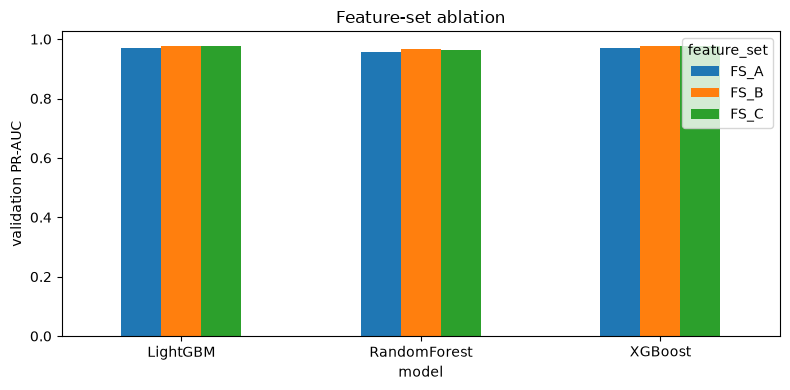

In [25]:
tr_sweep = case_balanced_sample(tr, SWEEP_MAX_TRAIN_ROWS, SEED)

if RUN_ABLATION:
    abl_rows = []
    for fs_name in ["FS_A", "FS_B", "FS_C"]:
        cols = fs[fs_name]
        for name in MODELS:
            if name == "RandomForest":
                model, seconds = fit_model(name, best_params[name], tr_rf[cols], tr_rf[TARGET].to_numpy())
            else:
                model, seconds = fit_model(name, best_params[name], tr_sweep[cols], tr_sweep[TARGET].to_numpy(),
                                           va[cols], yva)
            p = predict(model, va[cols])
            thr = best_threshold(yva, p)
            r = clf_metrics(yva, p, thr)
            r.update(rank_metrics(va["ts_id"].to_numpy(), yva, p))
            abl_rows.append({"feature_set": fs_name, "n_features": len(cols), "model": name,
                             "pr_auc": r["pr_auc"], "recall": r["recall"], "precision": r["precision"],
                             "f2": r["f2"], "r_precision": r["r_precision"], "fit_s": seconds})
    abl = pd.DataFrame(abl_rows)
    display(abl.pivot(index="model", columns="feature_set", values="pr_auc").rename_axis(columns="PR-AUC (validation)"))
    display(abl.pivot(index="model", columns="feature_set", values="r_precision").rename_axis(columns="R-precision (validation)"))
    abl.to_csv(RES_DIR + "/ablation_validation.csv", index=False)

    ax = abl.pivot(index="model", columns="feature_set", values="pr_auc").plot(kind="bar", figsize=(8, 4), rot=0)
    ax.set_ylabel("validation PR-AUC")
    ax.set_title("Feature-set ablation")
    plt.tight_layout()
    plt.show()

In [ ]:
LOCAL_ENG = ["heading_sin", "heading_cos", "rel_azimuth_sin", "rel_azimuth_cos", "rel_elevation", "radial_speed",
             "radial_speed_norm", "nn_dist_ratio", "is_isolated", "turn_saturated", "pitch_saturated"]


def feature_groups(cols):
    """Splits a list of feature names into the four groups."""
    env = [c for c in cols if c in fs["FS_C"] and c not in fs["FS_B"]]
    context = [c for c in cols if c in fs["FS_B"] and c not in fs["FS_A"]]
    local = [c for c in cols if c in LOCAL_ENG]
    raw = [c for c in cols if c not in env + context + local]
    groups = {"raw agent features": raw, "agent-local (engineered)": local,
              "swarm context (engineered)": context, "environment": env}
    # drop empty groups
    return {k: v for k, v in groups.items() if len(v) > 0}


if RUN_PERM_IMPORTANCE:
    groups = feature_groups(FEATS)
    print({k: len(v) for k, v in groups.items()})

    vs = va.sample(n=min(100000, len(va)), random_state=SEED)
    ys = vs[TARGET].to_numpy()

    importance = {}
    for name in MODELS:
        base = average_precision_score(ys, predict(models[name], vs[FEATS]))
        drops = {}
        for g in groups:
            gcols = groups[g]
            drop_values = []
            for r in range(3):                       # shuffle 3 times and average
                shuffled = vs[FEATS].copy()
                perm = np.random.default_rng(SEED + r).permutation(len(vs))
                shuffled[gcols] = vs[gcols].to_numpy()[perm]
                drop_values.append(base - average_precision_score(ys, predict(models[name], shuffled)))
            drops[g] = np.mean(drop_values)
        importance[name] = drops

    imp_tbl = pd.DataFrame(importance)
    print("PR-AUC drop on validation when a whole feature group is shuffled:")
    display(imp_tbl)
    imp_tbl.to_csv(RES_DIR + "/group_permutation_importance.csv")
    imp_tbl.plot(kind="barh", figsize=(9, 3.5))
    plt.xlabel("PR-AUC drop")
    plt.tight_layout()
    plt.show()

# importance of single features (gain), each model normalised to sum to 1
gain = {}
gain["RandomForest"] = pd.Series(models["RandomForest"].feature_importances_, index=FEATS)
gain["XGBoost"] = pd.Series(models["XGBoost"].get_booster().get_score(importance_type="gain")).reindex(FEATS).fillna(0)
gain["LightGBM"] = pd.Series(models["LightGBM"].booster_.feature_importance("gain"), index=FEATS)
gain = pd.DataFrame(gain)
gain = gain / gain.sum()
gain.sort_values("LightGBM", ascending=False).to_csv(RES_DIR + "/feature_importance_gain.csv")

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for k in range(3):
    name = MODELS[k]
    gain[name].sort_values().tail(15).plot(kind="barh", ax=axes[k])
    axes[k].set_title(name + ": top 15 by gain")
plt.tight_layout()
plt.show()

In [ ]:
if RUN_LEARNING_CURVE:
    lc_rows = []
    train_cases = np.array(sorted(tr["case_id"].unique()))
    for frac in [0.25, 0.5, 0.75, 1.0]:
        k = max(int(round(frac * len(train_cases))), 3)
        if frac < 1:
            n_repeats = 3
        else:
            n_repeats = 1
        for rep in range(n_repeats):
            chosen = np.random.default_rng(SEED + rep).choice(train_cases, size=k, replace=False)
            d = case_balanced_sample(tr[tr["case_id"].isin(chosen)], SWEEP_MAX_TRAIN_ROWS, SEED)
            for name in ["XGBoost", "LightGBM"]:
                model, _ = fit_model(name, best_params[name], d[FEATS], d[TARGET].to_numpy())
                lc_rows.append({"train_cases": k, "model": name, "rep": rep,
                                "val_pr_auc": average_precision_score(yva, predict(model, Xva))})

    lc = pd.DataFrame(lc_rows).groupby(["train_cases", "model"])["val_pr_auc"].agg(["mean", "std"]).reset_index()
    display(lc.pivot(index="train_cases", columns="model", values="mean"))

    fig, ax = plt.subplots(figsize=(7, 4))
    for name in ["XGBoost", "LightGBM"]:
        s = lc[lc["model"] == name]
        ax.errorbar(s["train_cases"], s["mean"], yerr=s["std"].fillna(0), marker="o", capsize=3, label=name)
    ax.set_xlabel("training cases")
    ax.set_ylabel("validation PR-AUC")
    ax.set_title("Learning curve over cases")
    ax.legend()
    plt.tight_layout()
    plt.show()
    lc.to_csv(RES_DIR + "/learning_curve.csv", index=False)

In [ ]:
# optional: 5-fold cross-validation over cases on train + val (set RUN_GROUP_CV = True)
if RUN_GROUP_CV:
    both = pd.concat([tr, va], ignore_index=True)
    folds = list(GroupKFold(n_splits=5).split(both, groups=both["case_id"]))
    n_trees = {"XGBoost": models["XGBoost"].best_iteration + 1, "LightGBM": models["LightGBM"].best_iteration_ + 1}

    cv_rows = []
    for name in MODELS:
        for k in range(len(folds)):
            train_part = both.iloc[folds[k][0]]
            test_part = both.iloc[folds[k][1]]
            if name == "RandomForest":
                sample = case_balanced_sample(train_part, RF_MAX_TRAIN_ROWS, SEED)
                model = make_rf(**best_params[name]).fit(sample[FEATS], sample[TARGET])
            elif name == "XGBoost":
                model = make_xgb(**{**best_params[name], "n_estimators": n_trees[name], "early_stopping_rounds": None})
                model.fit(train_part[FEATS], train_part[TARGET], verbose=False)
            else:
                model = make_lgb(**{**best_params[name], "n_estimators": n_trees[name]})
                model.fit(train_part[FEATS], train_part[TARGET])
            p = predict(model, test_part[FEATS])
            cv_rows.append({"model": name, "fold": k,
                            "pr_auc": average_precision_score(test_part[TARGET], p),
                            "r_precision": rank_metrics(test_part["ts_id"].to_numpy(), test_part[TARGET].to_numpy(), p)["r_precision"]})
    cv = pd.DataFrame(cv_rows)
    display(cv.groupby("model")[["pr_auc", "r_precision"]].agg(["mean", "std"]))
    cv.to_csv(RES_DIR + "/group_cv.csv", index=False)

## 11. Is it good enough?

The `TARGETS` from section 1 are checked against the test results with their bootstrap intervals. The weakest subsets are listed too, since an average can hide a condition where the models fail.

In [ ]:
rows = []
for name in MODELS + ["heuristic: criticality_score"]:
    row = {"model": name}
    for k in TARGETS:
        target_value = TARGETS[k]
        value = test_tbl.loc[name, k]
        row[k] = value
        row[k + " >= target"] = bool(value >= target_value)
        if (k + "_lo") in ci.columns:
            row[k + " CI low >= target"] = bool(ci.loc[name, k + "_lo"] >= target_value)
        else:
            row[k + " CI low >= target"] = np.nan
    rows.append(row)
verdict = pd.DataFrame(rows).set_index("model")
print("Targets:", TARGETS)
display(verdict)

best_model = val_tbl.loc[MODELS, "pr_auc"].idxmax()
print("\nBest on validation PR-AUC:", best_model)
heuristic_pr_auc = test_tbl.loc["heuristic: criticality_score", "pr_auc"]
print("Test PR-AUC", best_model, ":", round(test_tbl.loc[best_model, "pr_auc"], 3),
      "| heuristic criticality_score:", round(heuristic_pr_auc, 3), "| prevalence:", round(te_y.mean(), 3))
d = boot_df[best_model]["pr_auc"]
print("95% case-bootstrap interval for", best_model, "PR-AUC: [", round(d.quantile(0.025), 3), ",", round(d.quantile(0.975), 3), "]")

best_subsets = subs_test[(subs_test["model"] == best_model) & (subs_test["subset"] != "ALL")]
print("\nWeakest subsets for", best_model, "by recall:")
display(best_subsets.sort_values("recall").head(8)[["subset", "n_cases", "n_rows", "prevalence", "pr_auc", "recall", "precision", "r_precision"]])
print("PR-AUC range across subsets:", round(best_subsets["pr_auc"].min(), 3), "to", round(best_subsets["pr_auc"].max(), 3),
      "| recall range:", round(best_subsets["recall"].min(), 3), "to", round(best_subsets["recall"].max(), 3))

# save the test predictions, so GraphSAGE can later be compared on the same rows with the same thresholds
pred = te[["case_id", "step", "agent_id", "ts_id", TARGET, "strat_attrition", "strat_num_agents"]].copy()
for name in scores["test"]:
    pred["score: " + name] = scores["test"][name]
try:
    pred.to_parquet(RES_DIR + "/test_predictions.parquet", index=False)
except ImportError:
    pred.to_csv(RES_DIR + "/test_predictions.csv.gz", index=False)

# save the settings of this run
clean_params = {}
for name in best_params:
    clean_params[name] = {}
    for key in best_params[name]:
        value = best_params[name][key]
        if isinstance(value, np.generic):
            value = value.item()
        clean_params[name][key] = value
run_config = {"feature_set": FEATURE_SET, "thresholds": THR, "best_params": clean_params, "best_model_validation": best_model}
json.dump(run_config, open(RES_DIR + "/run_config.json", "w"), indent=2, default=str)
print("\nsaved to folder:", RES_DIR)

## 12. Ablation on the test split (FS_A vs FS_B vs FS_C)

Same model and hyperparameters for each feature set. The threshold is chosen on validation. Change `ABL_MODEL` to run it for another model.

In [21]:
ABL_MODEL = "LightGBM"

abl_rows = []
p_test_by_fs = {}
thr_by_fs = {}
for fs_name in ["FS_A", "FS_B", "FS_C"]:
    cols = fs[fs_name]
    model, fit_s = fit_model(ABL_MODEL, best_params[ABL_MODEL], tr[cols], ytr, va[cols], yva)

    p_val = predict(model, va[cols])
    thr = best_threshold(yva, p_val, beta=THRESHOLD_BETA)
    p_test = predict(model, te[cols])
    r = clf_metrics(yte, p_test, thr)
    rk = rank_metrics(ts_te, yte, p_test)
    best_iter = model.best_iteration_

    p_test_by_fs[fs_name] = p_test
    thr_by_fs[fs_name] = thr
    abl_rows.append({"feature_set": fs_name, "n_features": len(cols), "model": ABL_MODEL,
                     "test_pr_auc": r["pr_auc"], "test_roc_auc": r["roc_auc"],
                     "test_recall": r["recall"], "test_precision": r["precision"], "test_f2": r["f2"],
                     "test_r_precision": rk["r_precision"], "test_map": rk["map"],
                     "threshold_val": thr, "best_iter": best_iter, "fit_s": round(fit_s, 1)})

abl_test = pd.DataFrame(abl_rows).set_index("feature_set")
print("TEST ablation,", ABL_MODEL, "(threshold from validation, F" + str(THRESHOLD_BETA) + "):")
display(abl_test)
abl_test.to_csv(RES_DIR + "/ablation_test_" + ABL_MODEL + ".csv")

# sanity check: the FS_B row must match the headline numbers, because FEATURE_SET = "FS_B" in the main run
if ABL_MODEL in test_tbl.index and FEATURE_SET == "FS_B":
    print("headline", ABL_MODEL, "test PR-AUC", round(test_tbl.loc[ABL_MODEL, "pr_auc"], 4),
          "| FS_B row", round(abl_test.loc["FS_B", "test_pr_auc"], 4), "(should match)")

TEST ablation, LightGBM (threshold from validation, F2.0):


,n_features,model,test_pr_auc,test_roc_auc,test_recall,test_precision,test_f2,test_r_precision,test_map,threshold_val,best_iter,fit_s
feature_set,,,,,,,,,,,,
FS_A,29,LightGBM,0.9782,0.9835,0.9616,0.8609,0.9397,0.9244,0.9636,0.1925,436,18.1000
FS_B,45,LightGBM,0.9862,0.9892,0.9706,0.8826,0.9516,0.9337,0.9701,0.1842,242,14.3000
FS_C,51,LightGBM,0.9848,0.9881,0.9633,0.8858,0.9467,0.9335,0.9687,0.1780,288,17.0000


headline LightGBM test PR-AUC 0.9862 | FS_B row 0.9862 (should match)


## 13. Bootstrap intervals and paired differences between feature sets

The same resampled cases are used for every feature set, so the differences are fair.

In [ ]:
boot_fs = {}
for fs_name in p_test_by_fs:
    boot_fs[fs_name] = []

rb = np.random.default_rng(SEED)
for b in range(N_BOOT):
    drawn_cases = rb.choice(case_ids, size=len(case_ids), replace=True)
    idx = np.concatenate([case_rows[c] for c in drawn_cases])
    y = te_y[idx]
    for fs_name in p_test_by_fs:
        pp = p_test_by_fs[fs_name][idx]
        thr = thr_by_fs[fs_name]
        tp = ((pp >= thr) & (y == 1)).sum()
        boot_fs[fs_name].append([average_precision_score(y, pp),
                                 tp / max((y == 1).sum(), 1),
                                 tp / max((pp >= thr).sum(), 1)])

for fs_name in boot_fs:
    boot_fs[fs_name] = np.array(boot_fs[fs_name])        # columns: PR-AUC, recall, precision

metric_names = ["pr_auc", "recall", "precision"]

ci_rows = []
for fs_name in boot_fs:
    row = {"feature_set": fs_name}
    for j in range(3):
        m = metric_names[j]
        row[m] = abl_test.loc[fs_name, "test_" + m]
        row[m + "_lo"] = np.quantile(boot_fs[fs_name][:, j], 0.025)
        row[m + "_hi"] = np.quantile(boot_fs[fs_name][:, j], 0.975)
    ci_rows.append(row)
ci_tbl = pd.DataFrame(ci_rows).set_index("feature_set")
print("TEST ablation with 95% case-bootstrap intervals (", N_BOOT, "draws over", len(case_ids), "cases ):")
display(ci_tbl)

diff_rows = []
for a_name, b_name in [("FS_B", "FS_A"), ("FS_C", "FS_B"), ("FS_C", "FS_A")]:
    for j in range(3):
        d = boot_fs[a_name][:, j] - boot_fs[b_name][:, j]
        lo = np.quantile(d, 0.025)
        hi = np.quantile(d, 0.975)
        diff_rows.append({"comparison": a_name + " - " + b_name, "metric": metric_names[j], "mean_diff": d.mean(),
                          "lo": lo, "hi": hi, "significant": bool(lo > 0 or hi < 0)})
diff_tbl = pd.DataFrame(diff_rows)
print("Paired differences (the interval excludes 0 = significant):")
display(diff_tbl)

ci_tbl.to_csv(RES_DIR + "/ablation_test_ci_" + ABL_MODEL + ".csv")
diff_tbl.to_csv(RES_DIR + "/ablation_paired_diff_" + ABL_MODEL + ".csv", index=False)

## 14. Reading the results

- Compare models with the paired bootstrap rows in section 8. Differences smaller than their interval are noise at 20 test cases.
- If recall drops under heavy attrition, in large swarms or on promoted agents, structure beyond a single agent's features matters.
- If FS_C beats FS_B on validation but not on test, the environment variables act as a case fingerprint. Keep them out.
- Next step: reuse `processed/*_nn.parquet`, the same split and threshold rule for GraphSAGE. `results/test_predictions.parquet` holds each model's scores.